# Кластеризация и классификация текстовых данных

Цель работы:

Построить модель классификации на основе ранее полученных кластеров и научить систему автоматически определять тематическую группу фильма по его описанию.

В работе используются:

- TF-IDF векторизация;
- алгоритм KMeans;
- алгоритм KNN;
- оценка качества модели;
- сохранение обученных моделей.

In [1]:
import pandas as pd

import numpy as np

import re

import pickle

import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.cluster import KMeans

from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings

warnings.filterwarnings('ignore')

## Загрузка данных

In [2]:
films = pd.read_csv('top500_films.csv')

films.head()

,title,genre,year,country,rating,description
0,1+1,"драма, комедия",2011,Франция,8.9,"Пострадав в результате несчастного случая, бог..."
1,Джентльмены,"криминал, комедия, боевик",2019,"США, Великобритания",8.7,Один ушлый американец ещё со студенческих лет ...
2,Триггер,драма,2018,Россия,8.5,Психолог Артём Стрелецкий — сторонник шоковой ...
3,Гнев человеческий,"боевик, триллер",2021,"Великобритания, США",7.7,Грузовики лос-анджелесской инкассаторской комп...
4,Брат,"драма, криминал, боевик",1997,Россия,8.4,"Демобилизовавшись, Данила Багров возвращается ..."


In [3]:
films = films.fillna('')

films['document'] = (

    films['title']

    + ' '

    + films['genre']

    + ' '

    + films['description']

)

In [28]:
films['main_genre'] = films['genre'].apply(

    lambda x: str(x).split(',')[0].strip()

)

films['main_genre'].value_counts().head(15)

main_genre
драма          131
фантастика      46
комедия         45
боевик          40
триллер         39
мультфильм      29
фэнтези         26
криминал        20
мелодрама       16
приключения     15
анимация        11
биография       10
военный         10
ужасы            9
детектив         8
Name: count, dtype: int64

## Очистка текста

In [4]:
def preprocess_text(text):

    text = str(text)

    text = text.lower()

    text = re.sub(

        r'[^a-zа-яё\s]',

        ' ',

        text

    )

    text = re.sub(

        r'\s+',

        ' ',

        text

    )

    return text.strip()

films['document'] = films['document'].apply(

    preprocess_text

)

## TF-IDF представление текстов

In [5]:
vectorizer = TfidfVectorizer(

    max_features=4000,

    stop_words='english'

)

X = vectorizer.fit_transform(

    films['document']

)

print(X.shape)

(495, 4000)


## Построение кластеров

In [6]:
kmeans = KMeans(

    n_clusters=6,

    random_state=42

)

films['cluster'] = kmeans.fit_predict(X)

films[['title','cluster']].head()

,title,cluster
0,1+1,1
1,Джентльмены,3
2,Триггер,0
3,Гнев человеческий,0
4,Брат,0


## Подготовка обучающей выборки

In [55]:
genre_counts = films['main_genre'].value_counts()

valid_genres = genre_counts[
    genre_counts >= 5
].index

films_filtered = films[
    films['main_genre'].isin(valid_genres)
].copy()

print(f'Количество фильмов: {len(films_filtered)}')

print(f'Количество жанров: {films_filtered["main_genre"].nunique()}')

X = vectorizer.fit_transform(
    films_filtered['document']
)

y = films_filtered['main_genre']

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.2,

    random_state=42,

    stratify=y

)

Количество фильмов: 479
Количество жанров: 19


## Разделение выборки

In [56]:
from sklearn.model_selection import train_test_split

X = vectorizer.fit_transform(

    films_filtered['document']

)

y = films_filtered['main_genre']

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.2,

    random_state=42,

    shuffle=True

)

print(X_train.shape)

print(X_test.shape)

(383, 4000)
(96, 4000)


## Построение модели LinearSVC

In [57]:
from sklearn.svm import LinearSVC

In [58]:
svc_model = LinearSVC(

    random_state=42,

    max_iter=5000

)

svc_model.fit(

    X_train,

    y_train

)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,42


## Оценка качества модели

In [59]:
from sklearn.metrics import (

    accuracy_score,

    classification_report,

    confusion_matrix

)

svc_predictions = svc_model.predict(

    X_test

)

svc_accuracy = accuracy_score(

    y_test,

    svc_predictions

)

print(

    f'Точность модели: {svc_accuracy:.3f}'

)

Точность модели: 0.490


In [60]:
print(

    classification_report(

        y_test,

        svc_predictions

    )

)

              precision    recall  f1-score   support

    анимация       0.00      0.00      0.00         3
       аниме       0.00      0.00      0.00         1
   биография       0.00      0.00      0.00         2
      боевик       0.50      0.29      0.36         7
     вестерн       0.00      0.00      0.00         1
    детектив       0.00      0.00      0.00         2
       драма       0.45      0.90      0.60        31
     комедия       0.67      0.29      0.40         7
    криминал       0.00      0.00      0.00         8
   мелодрама       0.00      0.00      0.00         2
     мистика       0.00      0.00      0.00         1
  мультфильм       0.80      1.00      0.89         4
 приключения       0.00      0.00      0.00         4
    семейный       0.00      0.00      0.00         1
     триллер       0.33      0.14      0.20         7
       ужасы       0.00      0.00      0.00         2
  фантастика       0.69      0.90      0.78        10
     фэнтези       0.33    

In [61]:
matrix = confusion_matrix(

    y_test,

    svc_predictions

)

matrix

array([[ 0,  0,  0,  0,  0,  0,  3,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         1,  0],
       [ 0,  0,  0,  0,  0,  0,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0],
       [ 0,  0,  0,  2,  0,  0,  3,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         2,  0],
       [ 0,  0,  0,  0,  0,  0,  1,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  2,  0,
         0,  0],
       [ 0,  0,  1,  1,  0,  0, 28,  0,  0,  1,  0,  0,  0,  0,  0,  0,
         0,  0],
       [ 0,  0,  0,  0,  0,  0,  4,  2,  0,  0,  0,  0,  0,  0,  0,  0,
         1,  0],
       [ 0,  0,  0,  0,  0,  0,  7,  1,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0],
       [ 0,  0,  0,  0,  0,  0,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0],
       [ 0,  0,  0,  0,  0,  0,  1,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0],
       [ 0,  0,  0,  

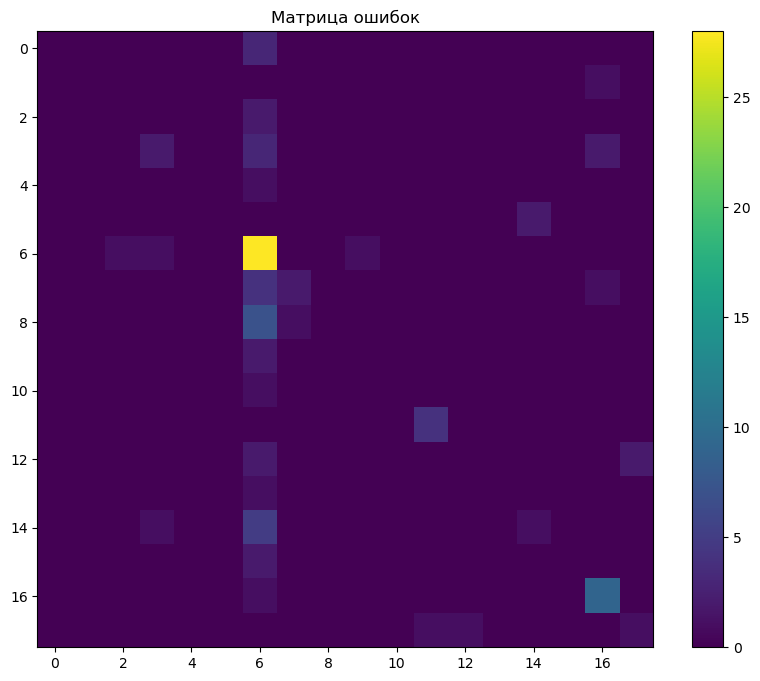

In [62]:
plt.figure(

    figsize=(10,8)

)

plt.imshow(

    matrix

)

plt.title(

    'Матрица ошибок'

)

plt.colorbar()

plt.show()

## Проверка работы модели

In [64]:
new_text = '''

Молодой детектив расследует серию загадочных убийств в футуристическом мегаполисе, пытаясь раскрыть тайну преступной организации.

'''

new_vector = vectorizer.transform(

    [new_text]

)

prediction = svc_model.predict(

    new_vector

)

print(

    f'Предсказанный жанр: {prediction[0]}'

)

Предсказанный жанр: драма


## Сохранение модели

In [65]:
with open(

    'model.pkl',

    'wb'

) as file:

    pickle.dump(

        svc_model,

        file

    )

with open(

    'vectorizer.pkl',

    'wb'

) as file:

    pickle.dump(

        vectorizer,

        file

    )

print(

    'Файлы успешно сохранены'

)

Файлы успешно сохранены


# Вывод

В ходе выполнения работы была проведена кластеризация и классификация текстовых данных.

Для предварительного разделения фильмов на тематические группы был использован алгоритм KMeans.

После этого была построена модель классификации LinearSVC, позволяющая автоматически определять основной жанр фильма по его описанию.

Для представления текстов применялась TF-IDF векторизация.

Полученная модель была сохранена и будет использована при разработке ML-приложения в следующей работе.